# c3 · Step 3: Preprocessing and dataloader

Two separate parts, as planned:
1. **Preprocessing** (deterministic, run once): image → fixed-size uint8 tensor, cached to `cache/`.
   One cache per variant that c5 will compare.
2. **Dataloader** (every epoch): the whole split lives on the GPU as uint8. Each batch is converted to float,
   **augmented (train only)**, then normalised.

Code lives in `lib/data.py`. This notebook builds, checks and visualises it.

In [1]:
import sys, time
import numpy as np, torch, matplotlib.pyplot as plt
sys.path.insert(0, "..")
from PIL import Image
from lib.data import (CLASSES, SEED, list_split, preprocess, head_mask, _bbox, build_cache, load_split,
                      GPUSplit, AUG_PRESETS, augment)
from lib.train import DEVICE
rng = np.random.default_rng(SEED)
print("device:", DEVICE)

device: mps


## 1. Geometry options
How to turn 349 different resolutions into one square size:

| Option | What it does | Risk |
|---|---|---|
| **stretch** | resize directly | distorts non-square images (mostly no_tumor), which is a visible class cue |
| **pad** | pad to square with black, then resize | adds black bars (mostly to no_tumor), which is a class cue |
| **crop** | crop to the head bounding box, pad the rest to square, resize | depends on the head detector working |

All three are built and compared in c5. Below: the same non-square images under each option.

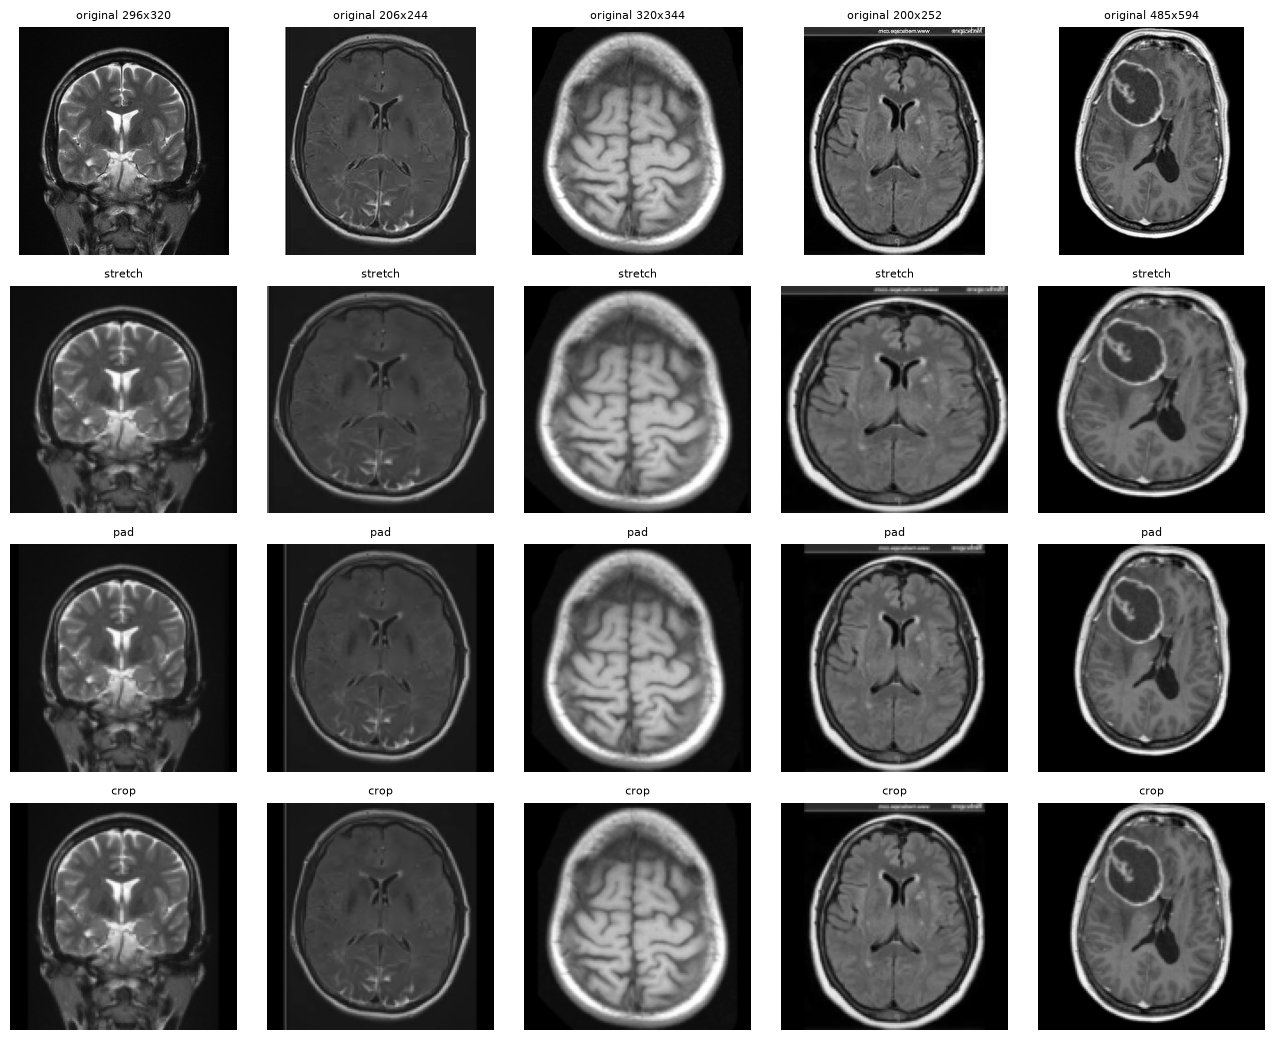

In [2]:
items = list_split("train")
nonsq = [p for p, c in items if (lambda im: im.width != im.height)(Image.open(p))]
pick = [nonsq[i] for i in rng.choice(len(nonsq), 5, replace=False)]
fig, axes = plt.subplots(4, 5, figsize=(13, 10.5))
for k, p in enumerate(pick):
    with Image.open(p) as im:
        axes[0, k].imshow(im.convert("L"), cmap="gray"); axes[0, k].set_title(f"original {im.width}x{im.height}", fontsize=8)
    for r, mode in enumerate(["stretch", "pad", "crop"], 1):
        axes[r, k].imshow(preprocess(p, "gray", mode, 128)[0], cmap="gray", vmin=0, vmax=255)
        axes[r, k].set_title(mode, fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 2. Does the head crop work?
The crop finds the largest bright connected region (blurred and thresholded, holes filled) and takes its bounding
box plus a 3 % margin. Check: the crop's share of the image area over **all** images, and the most extreme cases
by eye.

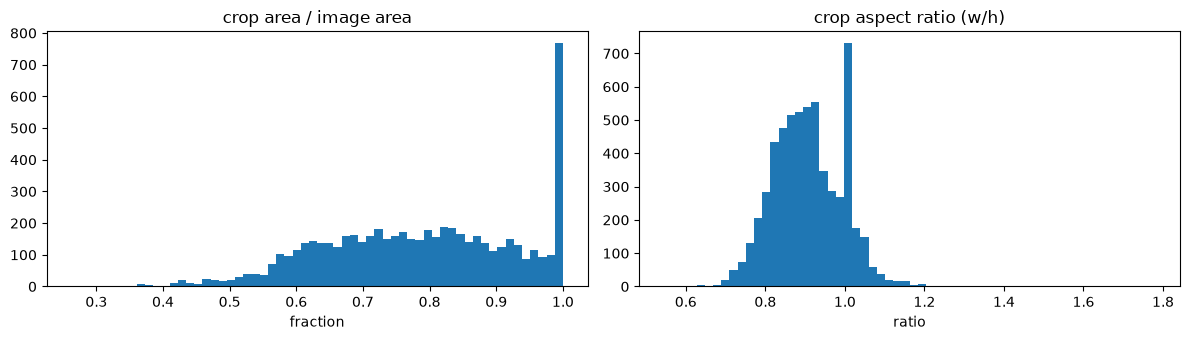

crop area: min 0.26, 1st pct 0.44, median 0.79
crops < 30 % of the image: 2 | aspect outside [0.6, 1.6]: 3


In [3]:
rows = []
for split in ["train", "val", "test"]:
    for p, c in list_split(split):
        g = np.asarray(Image.open(p).convert("L"))
        x0, y0, x1, y1 = _bbox(head_mask(g))
        rows.append((p, c, (x1 - x0) * (y1 - y0) / g.size, (x1 - x0) / max(y1 - y0, 1)))
area = np.array([r[2] for r in rows]); aspect = np.array([r[3] for r in rows])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(area, 60); ax[0].set(title="crop area / image area", xlabel="fraction")
ax[1].hist(aspect, 60); ax[1].set(title="crop aspect ratio (w/h)", xlabel="ratio")
plt.tight_layout(); plt.show()
print(f"crop area: min {area.min():.2f}, 1st pct {np.percentile(area, 1):.2f}, median {np.median(area):.2f}")
print(f"crops < 30 % of the image: {(area < 0.3).sum()} | aspect outside [0.6, 1.6]: {((aspect < 0.6) | (aspect > 1.6)).sum()}")

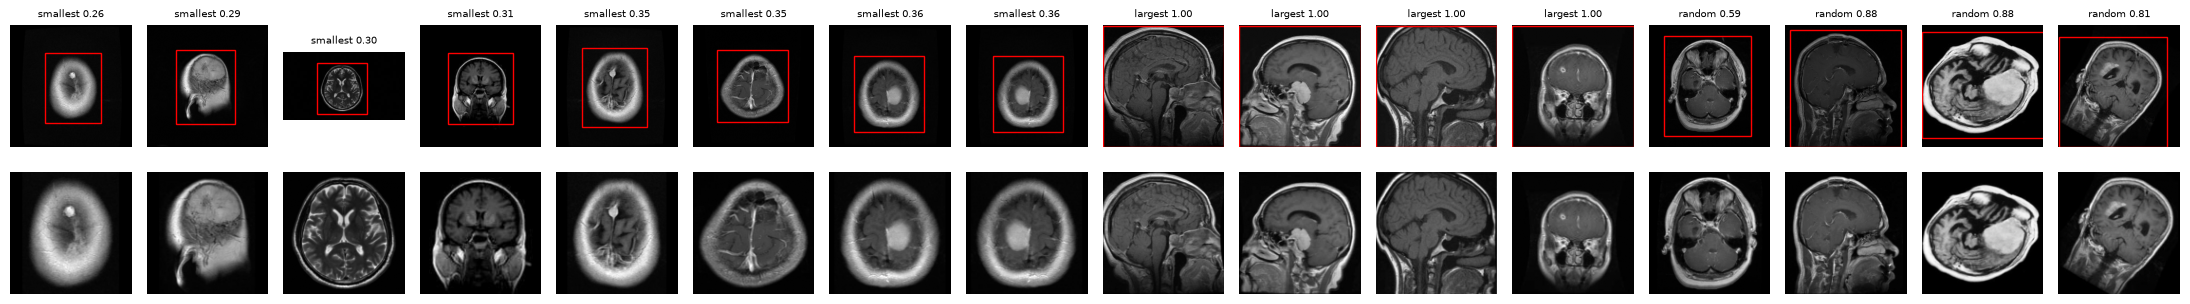

In [4]:
order = np.argsort(area)
show = list(order[:8]) + list(order[-4:]) + list(rng.choice(len(rows), 4, replace=False))
fig, axes = plt.subplots(2, 16, figsize=(22, 3.4))
for k, i in enumerate(show):
    p = rows[i][0]
    g = np.asarray(Image.open(p).convert("L")); x0, y0, x1, y1 = _bbox(head_mask(g))
    axes[0, k].imshow(g, cmap="gray"); axes[0, k].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="r", lw=1))
    axes[0, k].set_title(("smallest" if k < 8 else "largest" if k < 12 else "random") + f" {area[i]:.2f}", fontsize=7)
    axes[1, k].imshow(preprocess(p, "gray", "crop", 128)[0], cmap="gray")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

**Result.**
* The first version of the detector kept only the *largest* bright region. When the skull ring was broken into
  pieces, it cropped a fragment instead (an eye socket, part of the brain). That is dangerous: a crop that cuts out
  the tumour silently changes the label.
* The fixed version (union of all sizeable regions, `lib.data.head_mask`) leaves 2 crops below 30 % of the image.
  The smallest cases above are now all genuinely small heads in large frames, correctly cropped. Median crop is
  79 % of the image.

**Decision.** The crop option is reliable enough to enter the c5 comparison.

## 3. Build the caches (run once)
Every variant needed in c5: three geometries at 128 px, resolutions 64/192 for the chosen geometry,
and a 3-channel version. Each is preprocessed once with 4 worker processes and saved as a uint8 tensor.

In [5]:
VARIANTS = [("gray", "stretch", 128), ("gray", "pad", 128), ("gray", "crop", 128),
            ("gray", "crop", 64), ("gray", "crop", 192), ("rgb", "crop", 128)]
for mode, resize, size in VARIANTS:
    t = time.time()
    shapes = [tuple(build_cache(s, mode, resize, size)["X"].shape) for s in ["train", "val", "test"]]
    print(f"{mode:4s} {resize:7s} {size:3d}: {shapes}  ({time.time() - t:.0f}s)")

gray stretch 128: [(4160, 1, 128, 128), (892, 1, 128, 128), (889, 1, 128, 128)]  (0s)
gray pad     128: [(4160, 1, 128, 128), (892, 1, 128, 128), (889, 1, 128, 128)]  (0s)
gray crop    128: [(4160, 1, 128, 128), (892, 1, 128, 128), (889, 1, 128, 128)]  (0s)
gray crop     64: [(4160, 1, 64, 64), (892, 1, 64, 64), (889, 1, 64, 64)]  (0s)


gray crop    192: [(4160, 1, 192, 192), (892, 1, 192, 192), (889, 1, 192, 192)]  (0s)
rgb  crop    128: [(4160, 3, 128, 128), (892, 3, 128, 128), (889, 3, 128, 128)]  (0s)


## 4. Normalisation statistics (train only)

In [6]:
for mode, resize, size in VARIANTS:
    X = load_split("train", mode, resize, size)["X"].float() / 255
    print(f"{mode:4s} {resize:7s} {size:3d}: mean {X.mean():.4f}  std {X.std():.4f}")

gray stretch 128: mean 0.1749  std 0.1840
gray pad     128: mean 0.1719  std 0.1827


gray crop    128: mean 0.1942  std 0.1845
gray crop     64: mean 0.1942  std 0.1766


gray crop    192: mean 0.1942  std 0.1874


rgb  crop    128: mean 0.1942  std 0.1845


The statistics barely differ between variants (mean 0.17-0.19, std about 0.18). Each run computes its own from
its train split (`lib.train.prepare_data`), so val and test never leak into them. The alternative, per-image
standardisation, is a c5 option.

## 5. Dataloader checks
* shapes, dtype and value range of a normalised batch
* the weighted sampler really balances classes
* speed of one pass over train

In [7]:
tr = load_split("train", "gray", "crop", 128)
Xf = tr["X"].float() / 255
train = GPUSplit(tr, DEVICE, Xf.mean().item(), Xf.std().item())
gen = torch.Generator().manual_seed(SEED)
x, y = next(train.batches(64, shuffle=True, gen=gen))
print("batch:", tuple(x.shape), x.dtype, x.device, f"mean {x.mean():.3f} std {x.std():.3f}")

counts = torch.bincount(train.y.cpu(), minlength=4).float()
w = (1 / counts)[train.y.cpu()]
seen = torch.cat([y.cpu() for _, y in train.batches(64, gen=gen, weights=w)])
print("class share, plain shuffle   :", (counts / counts.sum()).numpy().round(3))
print("class share, weighted sampler:", (torch.bincount(seen, minlength=4) / len(seen)).numpy().round(3))

for aug in ["none", "strong"]:
    t = time.time()
    for x, y in train.batches(64, shuffle=True, gen=gen, aug=AUG_PRESETS[aug]):
        pass
    torch.mps.synchronize() if DEVICE.type == "mps" else None
    print(f"one pass over train, aug={aug}: {time.time() - t:.2f}s")

batch: (64, 1, 128, 128) torch.float32 mps:0 mean -0.083 std 0.920
class share, plain shuffle   : [0.369 0.249 0.132 0.25 ]
class share, weighted sampler: [0.25  0.26  0.242 0.247]


one pass over train, aug=none: 0.11s


one pass over train, aug=strong: 2.02s


## 6. Augmentation preview
Augmentation is implemented now but only switched on in c8 (regularisation). Here it is only checked by eye:
every augmented image must still look like a plausible scan of the same class.

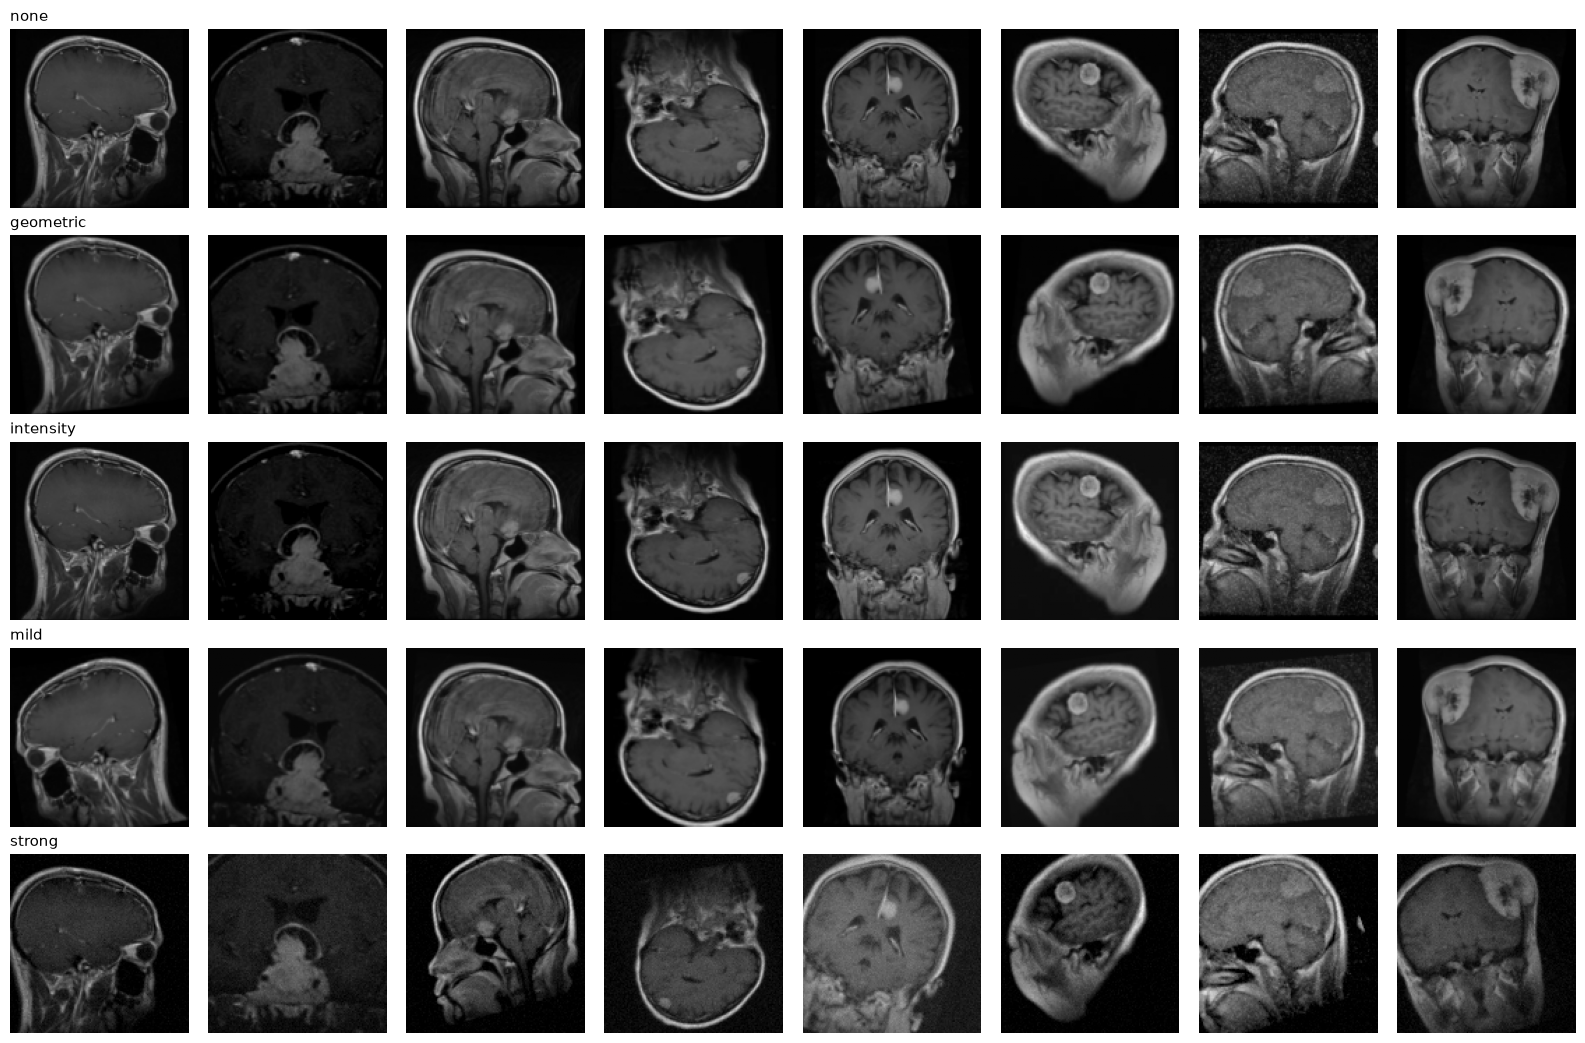

{'geometric': {'rot': 10, 'trans': 0.05, 'scale': (0.95, 1.05), 'hflip': 0.5}, 'intensity': {'brightness': 0.05, 'contrast': 0.1, 'gamma': 0.15, 'noise': 0.0}, 'mild': {'rot': 10, 'trans': 0.05, 'scale': (0.95, 1.05), 'hflip': 0.5, 'brightness': 0.05, 'contrast': 0.1, 'gamma': 0.15}, 'strong': {'rot': 20, 'trans': 0.1, 'scale': (0.85, 1.15), 'hflip': 0.5, 'brightness': 0.1, 'contrast': 0.2, 'gamma': 0.3, 'noise': 0.02}}


In [8]:
idx = torch.tensor(rng.choice(len(train), 8, replace=False))
x0 = train.X[idx.to(DEVICE)].float() / 255
fig, axes = plt.subplots(5, 8, figsize=(16, 10.5))
for r, name in enumerate(["none", "geometric", "intensity", "mild", "strong"]):
    xa = augment(x0, AUG_PRESETS[name], torch.Generator().manual_seed(r)).cpu()
    for k in range(8):
        axes[r, k].imshow(xa[k, 0], cmap="gray", vmin=0, vmax=1); axes[r, k].axis("off")
    axes[r, 0].set_title(name, loc="left", fontsize=11)
plt.tight_layout(); plt.show()
print({k: v for k, v in AUG_PRESETS.items() if k != "none"})

**Check by eye.**
* *geometric* and *mild* produce plausible scans (small tilt, shift, zoom, left/right mirror).
* *strong* sometimes pushes part of the head out of frame and visibly adds noise, so it is the upper bound to test.

**Speed.** One pass over train takes 0.1 s without augmentation and 2 s with *strong*, so augmentation costs
about 2 s per epoch.

## Decisions

| Decision | Choice | Why |
|---|---|---|
| Where preprocessing runs | once, cached as uint8 tensors per variant (`cache/`) | deterministic; re-doing it every epoch wastes time |
| Where augmentation runs | on the GPU, per batch, train only | must differ every epoch; val/test stay untouched |
| Geometry candidates | stretch / pad / crop, all cached | chosen in c5 |
| Head crop | union-of-regions detector | the largest-region version cropped away anatomy |
| Normalisation | train mean/std per variant (per-image as a c5 option) | no val/test statistics leak in |
| Class balancing | weighted sampler implemented and verified (0.37/0.25/0.13/0.25 → about 0.25 each) | used only if c6 says so |
| Augmentation presets | none / geometric / intensity / mild / strong | tested in c8 |